# KQC Quick demo mask: Demo chips in a smiley on a 6-inch wafer (Quantcore PDK rebuild)

**What it is.** KQCircuits' fast demo mask (`scripts/masks/quick_demo.py`, `MaskSet(name="Quick", version=1,
with_grid=False)`; © IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../scripts/masks/quick_demo.py`; spec `docs/designs/kqc/quick_demo_mask.md`). It is one
mask layout on face `1t1`: a 15 × 15 chip map on KQC's default 6-inch wafer (`wafer_rad` 76 200 µm, 10 mm chips,
`dice_width` 200 µm). A ring of 36 `Demo` chips (`DE1`) and 17 empty KQC `Chip`s (`CH1`) for the eyes and the mouth
draw a smiley; every other map cell is empty (`---`).

This notebook rebuilds the mask with the library's wafer assembly (`quantcore_circuits.layouts.wafers.wafer.Wafer`)
on the Quantcore PDK. It is a rebuild, not a replica, distributed under GPL-3.0. The table says what is kept and what
the PDK changes.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| wafer | 6 in, `wafer_rad` 76 200 µm, a plain circle | the same 152.4 mm diameter, with the PDK's V-notch (1 mm deep) at the bottom; outline on 500/0 |
| chip grid | 15 × 15 map with a 10 mm pitch, centred: the middle cell sits on the wafer centre | the same positions and centring (`align="centre"`), as 10 mm dies with a 200 µm dicing street between them, so the pitch is 10.2 mm |
| dicing | `dice_width` 200 µm, the dicing edge inside each chip's KQC frame | a 200 µm street between the dies, and the PDK frame's L dicing markers (1000/0) in each chip's corners |
| edge rule | chips within `wafer_rad` minus `edge_clearance` (5 mm) of the centre | the PDK edge exclusion, 3 mm: all 53 mapped dies fit (Design 1) |
| DE1 | KQC `Demo`, built by the mask set with `with_grid=False` | the [Demo chip](demo.md) rebuild exactly as saved (`examples/designs/kqc/demo.json`, only read): Quantcore frame, launchers on the pad rule, trilayer SQUIDs and the cheese its build draws |
| CH1 | KQC `Chip` with its defaults: KQC's ChipFrame and nothing else | a 10 mm Quantcore die: KQC's `Chip` cell with its frame off and the PDK die frame (dicing L's, alignment grids, boundary 100/0, device ID "CH1") |
| empty cells | nothing drawn | grid positions that fit on the wafer stay empty dies: a 30 µm die outline and the die name on 501/0 |
| labels and marks | KQC position labels, KQC mask markers, the mask name | die names by the PDK wafer rule (rows A, B ... from the top, columns 1, 2 ... from the left), alignment crosses on 501/0, the mask name "QUICK V1" (written by this notebook, the wafer class has no mask label) |
| mask layers | `base_metal_gap` → "1", `underbump_metallization` → "2", `indium_bump` → "3" | the chips' build layers in the wafer file (Fab 1); the PDK fab layers (1/0 base etch, 3/0 keep-out, junction and airbridge layers, the frame) in the fab wafer (Fab 2) |
| netlists | two alternative netlists for DE1 (`alt_netlists`) | not used here: the Demo chip's netlist and LOM are in its own notebook |

**How this notebook goes.** The **Design** builds the wafer in five segments, each with a picture: the wafer and its
die grid, the chip map, the Demo chip (DE1), the empty chip (CH1), the whole wafer. **Check** compares the die count
and the map with the source cell by cell and checks the chips against their dies. LOM and Simulate have nothing of
their own here (one line each). **Fab** writes the wafer OAS with its die table and the fab-layer wafer.

**Nothing here solves.** The switches (the code cell after Setup) are kept so every design notebook starts the same
way; the mask has no FEM job of its own.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in Fab 2.
The segment pictures go to `build/snapshots/quick_demo_mask/` and the wafer files to `build/wafer/` (neither is
kept in the repo).

`LIVE`: with KLayout open (the default) the CH1 chip of Design 4 is pushed to the KLayout window as it is built;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the save check).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from collections import Counter
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, the save check
from kqcircuits.pya_resolver import pya
from quantcore_circuits.assembly import build, write_layout
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.wafers.wafer import Wafer

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")               # the CH1 design JSON (in quick_demo_mask/)
STEPS = Path("build/snapshots/quick_demo_mask")  # segment pictures (build/ is not kept in the repo)
WAFER = Path("build/wafer")                      # the wafer OAS, its die table and the chip files
CHIPS = WAFER / "chips" / "quick_demo_mask"

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (unused here: no target)

## The Quantcore PDK this mask uses

The chip rules come from the PDK object (`get_pdk()`), the wafer rules from the wafer class defaults
(`quantcore_circuits.layouts.wafers.wafer`), not from this notebook. The chips bring their own rules: the frame, the
pad rule and the junctions of the Demo chip are applied in its own design; CH1 uses the frame only. At wafer level
the mask uses the outline and marker layers, the edge exclusion, the street and the notch.

In [4]:
from dataclasses import fields
from quantcore_circuits.layouts.wafers import wafer as wafer_rules
from quantcore_circuits.pdk import QCC_LAYERS

display(Markdown(pdk_facts_md()))
WD = {f.name: f.default for f in fields(Wafer) if f.init}
presets = ", ".join(f"{k:g} mm ({v[1]})" for k, v in wafer_rules.PRESETS.items())
display(Markdown("\n".join([
    "| wafer rule | value |", "|---|---|",
    f"| outline | {QCC_LAYERS['wafer_boundary']} `wafer_boundary`: a 200 µm ring just inside the rim, notch cut in |",
    f"| die marks | {QCC_LAYERS['wafer_markers']} `wafer_markers`: die names, 30 µm die outlines, alignment crosses |",
    f"| edge exclusion | {WD['edge_mm']:g} mm from the rim and the notch (`edge_mm`) |",
    f"| dicing street | {WD['street_mm']:g} mm by default (`street_mm`) |",
    f"| orientation | {WD['orientation']} at the {WD['orientation_side']}, {wafer_rules.NOTCH_DEPTH_MM:g} mm deep |",
    f"| presets | {presets} |",
])))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | 5 µm squares, 20 µm gaps, ≥ 4 µm from the 3/0 keep-outs: a band of 3 rows around them, or the whole die (`cheese: "chip"`); an original design's own rule or holes where it has them (chip param `cheese`: auto / pdk / chip / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

| wafer rule | value |
|---|---|
| outline | qcc_wafer_boundary (500/0) `wafer_boundary`: a 200 µm ring just inside the rim, notch cut in |
| die marks | qcc_wafer_markers (501/0) `wafer_markers`: die names, 30 µm die outlines, alignment crosses |
| edge exclusion | 3 mm from the rim and the notch (`edge_mm`) |
| dicing street | 0.1 mm by default (`street_mm`) |
| orientation | notch at the bottom, 1 mm deep |
| presets | 100 mm (4 in), 150 mm (6 in) |

# Design: the wafer, one segment at a time

A wafer is laid out the way a mask is planned: the wafer and the grid of die positions first, then which chip goes
where, then the chips themselves, then everything together. Each segment is one cell with one picture.

| segment | what is placed here |
|---|---|
| 1 | the 152.4 mm wafer and its grid of 10 mm dies with 200 µm streets (no chips yet) |
| 2 | the chip map: KQC's smiley, read onto the die grid |
| 3 | DE1: the Demo chip, built once from its saved design |
| 4 | CH1: the empty chip, a 10 mm Quantcore die with the frame (saved as this notebook's design) |
| 5 | the whole wafer: both chips on their dies, the mask name, zooms on one die and on a street crossing |

## Design 1 · The wafer and its die grid

`Wafer(...)` packs square dies on the wafer and names them; it draws nothing yet. The numbers are the source's:
152.4 mm (KQC's `wafer_rad` 76 200 µm), 10 mm chips, 200 µm dicing. `align="centre"` puts one die on the wafer
centre, as KQC's map does with its middle cell; the default `"auto"` would pick the alignment with the most dies
(138 here) and shift the grid. `packing="dense"` (the default) keeps every position that lies completely inside the
usable disc: the wafer radius minus the 3 mm edge exclusion, clear of the notch.

The pitch is 10.2 mm, not KQC's 10 mm: KQC's dicing edge is part of each 10 mm chip, the PDK dies keep a street
between them. The table shows what that costs. On the PDK's 150 mm "6 in" preset, the eight ring dies closest to the
rim (B3, B11, C2, C12, K2, K12, L3 and L11, whose far corners are 72.34 mm from the centre) do not fit inside the
72 mm usable radius; on the source's 152.4 mm wafer (73.2 mm usable) all 53 mapped dies fit.

The picture is the empty grid: every die outline and name on 501/0, the outline ring on 500/0, the notch at the
bottom and the alignment crosses at the other three axis points.

| wafer | die + street | pitch | dies | mapped cells with no die |
|---|---|---|---|---|
| 152.4 mm (this mask) | 10 + 0.2 mm | 10.2 mm | 137 | 0 |
| 150 mm (PDK 6 in preset) | 10 + 0.2 mm | 10.2 mm | 129 | 8 |
| 152.4 mm (KQC's 10 mm pitch) | 10 + 0 mm | 10 mm | 137 | 0 |

137 dies, rows A to M; first A5, last M9
die at the wafer centre: G7


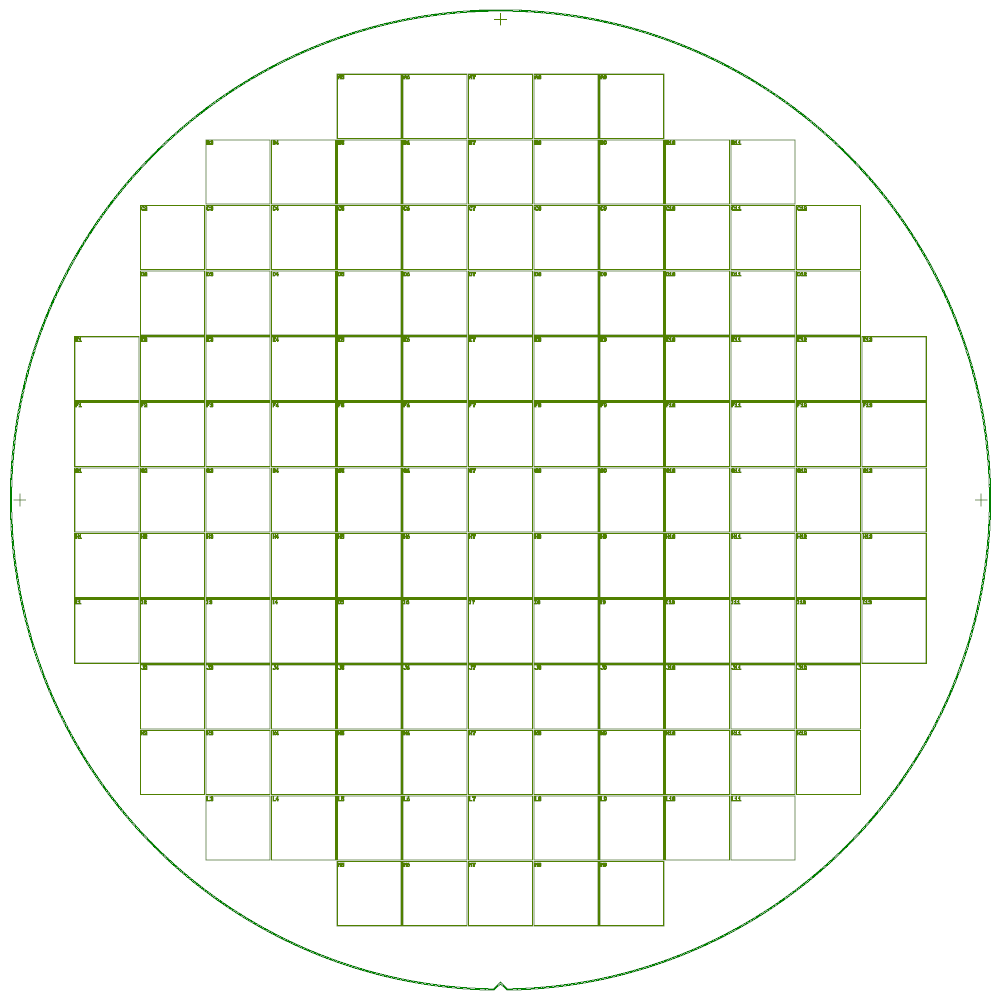

In [5]:
# the mask's map (KQC quick_demo.py, rows top to bottom): D = "DE1" (Demo), C = "CH1" (Chip), . = "---" (no chip)
KQC_MAP = [
    "...............", "...............", "...DDDDDDDDD...", "..D.........D..", "..D.CC...CC.D..",
    ".D..CC...CC..D.", ".D...........D.", ".D...........D.", ".D.C.......C.D.", ".D..C.....C..D.",
    "..D..CCCCC..D..", "..D.........D..", "...DD.....DD...", ".....DDDDD.....", "...............",
]
MID = len(KQC_MAP) // 2                          # the middle cell of the map sits on the wafer centre

w = Wafer(diameter_mm=152.4, die_mm=10.0, street_mm=0.2, edge_mm=3.0, align="centre", name="Quick")
PITCH = w.die_mm + w.street_mm


def map_cell(die, pitch=PITCH):
    # (row, column) of a die in the 15 x 15 map, 0-based from the top-left
    return MID - round(die.y_mm / pitch), MID + round(die.x_mm / pitch)


def off_wafer(wafer):
    # mapped cells (DE1 / CH1) that get no die on this wafer
    pitch = wafer.die_mm + wafer.street_mm
    cells = {map_cell(d, pitch) for d in wafer.dies}
    return [(r, c) for r, row in enumerate(KQC_MAP) for c, ch in enumerate(row) if ch != "." and (r, c) not in cells]


rows = ["| wafer | die + street | pitch | dies | mapped cells with no die |", "|---|---|---|---|---|"]
for diam, street, note in ((152.4, 0.2, "this mask"), (150.0, 0.2, "PDK 6 in preset"), (152.4, 0.0, "KQC's 10 mm pitch")):
    t = Wafer(diameter_mm=diam, die_mm=10.0, street_mm=street, edge_mm=3.0, align="centre")
    rows.append(f"| {diam:g} mm ({note}) | 10 + {street:g} mm | {10 + street:g} mm | {t.die_count} | {len(off_wafer(t))} |")
display(Markdown("\n".join(rows)))
print(f"{w.die_count} dies, rows {w.dies[0].row} to {w.dies[-1].row}; first {w.dies[0].name}, last {w.dies[-1].name}")
print("die at the wafer centre:", next(d.name for d in w.dies if d.x_mm == 0 and d.y_mm == 0))


def show_layout(layout, png, box=None, size=(1000, 1000), width=480):
    # write a wafer layout next to its picture and render it headless (KLayout)
    oas = Path(png).with_suffix(".oas")
    oas.parent.mkdir(parents=True, exist_ok=True)
    layout.write(str(oas))
    return snap_file(oas, png, box=box, size=size, width=width)


grid_layout, _ = w.build()                       # no chips: outline, die outlines and names, crosses
show_layout(grid_layout, STEPS / "1_grid.png");

## Design 2 · The chip map: KQC's smiley on the die grid

The map is read onto the dies by position: the die centred at (x, y) is map cell (row, column) = (7 − y / pitch,
7 + x / pitch), counted from the top-left, so the map's middle cell is the wafer's centre die. `ROLE` gives every
die its chip, `DE1`, `CH1` or none. Every die of the grid lands inside the 15 × 15 map: the outermost map rows and
columns lie beyond the wafer's edge exclusion, and the source leaves them empty too.

The picture is the die map (`Wafer.plot_map`) with the two chips coloured.

DE1 (Demo): 36 dies: B3, B4, B5, B6, B7, B8, B9, B10, B11, C2, C12, D2, D12, E1, E13, F1, F13, G1, G13, H1, H13, I1, I13, J2, J12, K2, K12, L3, L4, L10, L11, M5, M6, M7, M8, M9
CH1 (Chip): 17 dies: D4, D5, D9, D10, E4, E5, E9, E10, H3, H11, I4, I10, J5, J6, J7, J8, J9
empty:      84 dies


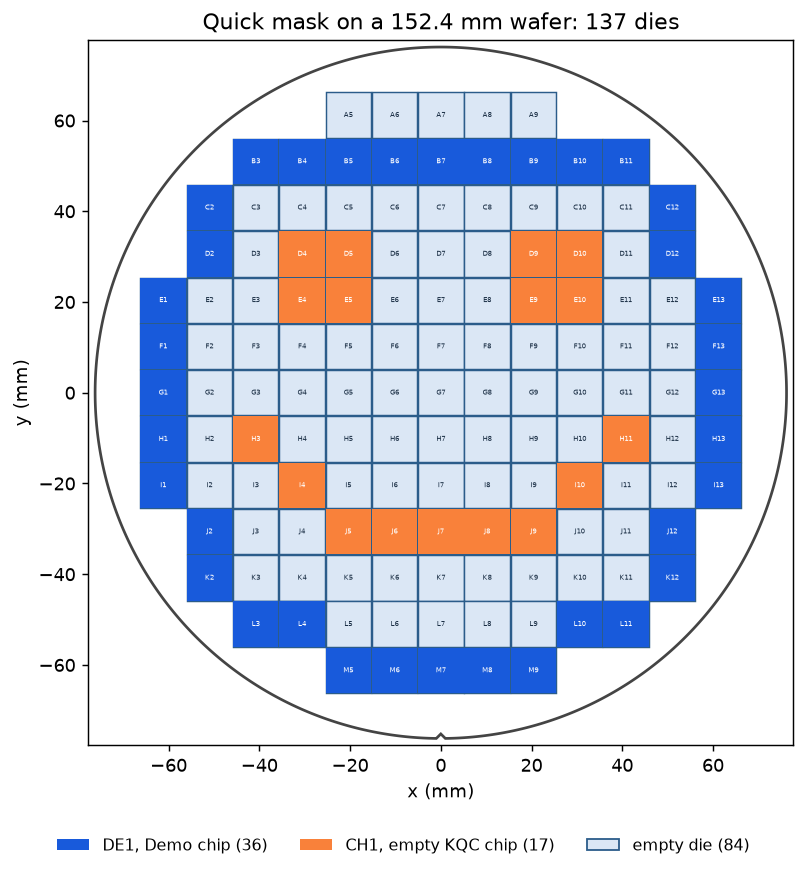

In [6]:
LEGEND = {"D": "DE1", "C": "CH1"}
ROLE = {}
for die in w.dies:
    r, c = map_cell(die)
    ROLE[die.name] = LEGEND.get(KQC_MAP[r][c])
by_role = {k: [n for n, v in ROLE.items() if v == k] for k in ("DE1", "CH1", None)}
print("DE1 (Demo):", len(by_role["DE1"]), "dies:", ", ".join(by_role["DE1"]))
print("CH1 (Chip):", len(by_role["CH1"]), "dies:", ", ".join(by_role["CH1"]))
print("empty:     ", len(by_role[None]), "dies")


def plot_chip_map(wafer, roles, png, width=520):
    # Wafer.plot_map with the DE1 and CH1 dies filled; returns the PNG
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch, Rectangle
    from quantcore_circuits.plots import COLORS

    colour = {"DE1": COLORS[0], "CH1": COLORS[1]}
    fig, ax = plt.subplots(figsize=(7, 7.4))
    wafer.plot_map(ax=ax, size_in=7)
    for die, text in zip(wafer.dies, ax.texts):
        role = roles[die.name]
        if role:
            x0, y0, x1, y1 = (v / 1000 for v in die.box_um)
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc=colour[role], ec="none", zorder=1.5))
            text.set_color("white")
    n = Counter(roles.values())
    ax.set_title(f"Quick mask on a {wafer.diameter_mm:g} mm wafer: {wafer.die_count} dies")
    fig.legend(handles=[Patch(fc=COLORS[0], label=f"DE1, Demo chip ({n['DE1']})"),
                        Patch(fc=COLORS[1], label=f"CH1, empty KQC chip ({n['CH1']})"),
                        Patch(fc="#dbe7f5", ec="#2b5c8a", label=f"empty die ({n[None]})")],
               loc="lower center", ncol=3, frameon=False, fontsize=9)
    fig.subplots_adjust(bottom=0.1)
    Path(png).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(png, dpi=130, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(png), width=width))
    return Path(png)


plot_chip_map(w, ROLE, STEPS / "2_map.png");

## Design 3 · DE1: the Demo chip, built once

DE1 is the [Demo chip](demo.md) exactly as its notebook saved it: `examples/designs/kqc/demo.json` is only read,
built here once, and written once to `build/wafer/chips/quick_demo_mask/DE1.oas`. The wafer takes that file: it
loads each distinct chip file once and places it as one sub-cell, so the 36 Demo dies are 36 instances of one cell
(checked in Design 5), not 36 builds.

The source's mask set builds its chips with `with_grid=False`; the rebuild places the Demo chip with the cheese of
its own design, whatever the chip's cheese rule draws (printed below). The chip is centred on its die by its 100/0
chip boundary, which must fit inside the 10 mm die.

DE1: examples\designs\kqc\demo.json → build\wafer\chips\quick_demo_mask\DE1.oas (63 kB)
chip boundary (0,0;10000,10000) µm; cheese 'chip', 124,282 holes in the build


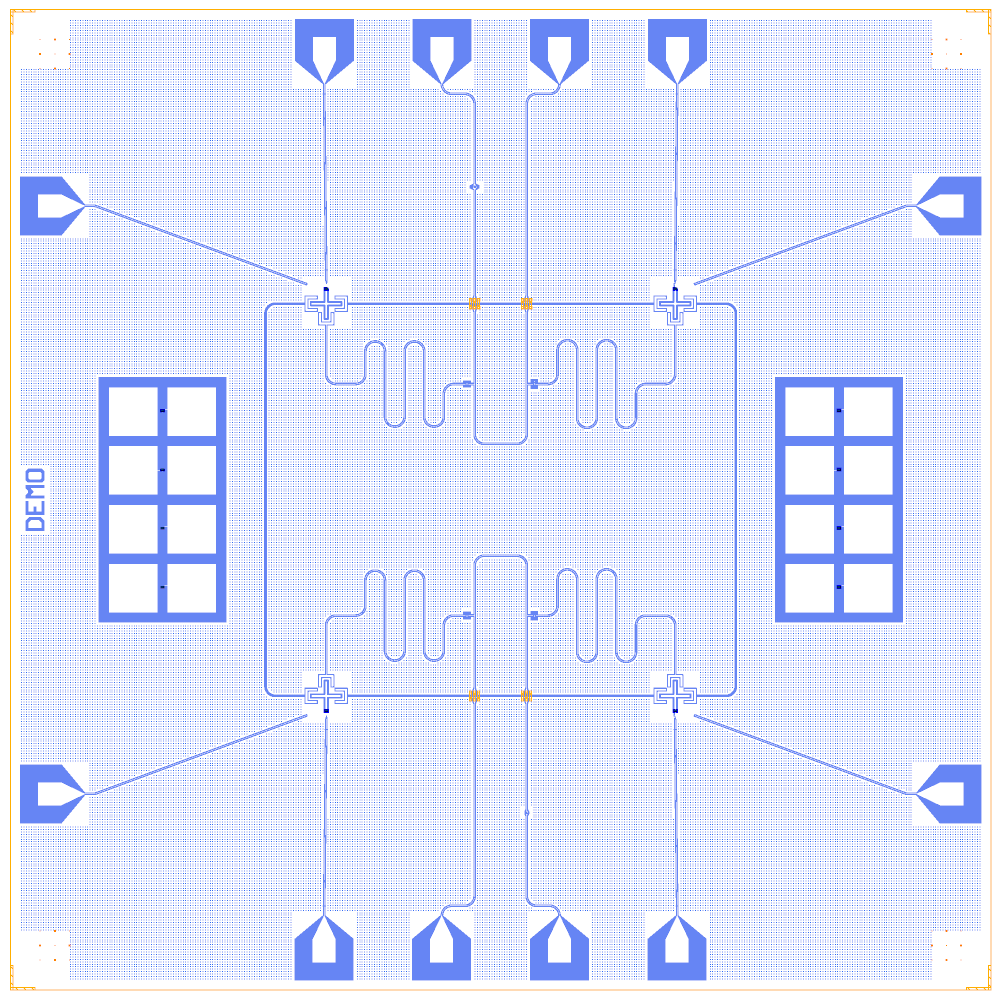

In [7]:
from quantcore_circuits.assembly.plan import cheese_mode
from quantcore_circuits.layouts.wafers.fab_export import build_cheese

DEMO_JSON = Path("examples/designs/kqc/demo.json")   # the Demo chip's own design file (read only)
demo = build(DEMO_JSON)
DE1 = write_layout(demo, CHIPS / "DE1.oas", sidecar=False)


def chip_box(path):
    # the 100/0 chip boundary of a chip file, in µm
    ly = pya.Layout()
    ly.read(str(path))
    return ly.top_cell().dbbox_per_layer(ly.find_layer(QCC_LAYERS["chip_boundary"]))


print(f"DE1: {DEMO_JSON} → {DE1} ({DE1.stat().st_size / 1e3:.0f} kB)")
print(f"chip boundary {chip_box(DE1)} µm; cheese '{cheese_mode(demo.design)}', "
      f"{build_cheese(demo.cell, demo.design.pdk):,} holes in the build")
snap_file(DE1, STEPS / "3_de1.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## Design 4 · CH1: the empty chip (this notebook's design)

CH1 is KQC's base `Chip` PCell with its defaults: in the source it draws KQC's chip frame and nothing else. Here the
cell is placed at the chip origin with `frames_enabled=[]`, so KQC draws no `ChipFrame`, and the Designer chip draws
the Quantcore die frame instead: L dicing markers on 1000/0, 3 × 3 alignment grids on 1001/0, the chip boundary on
100/0 and the device ID "CH1". The cheese is the PDK default (`"auto"`): the band of holes round what the chip draws,
here only the device ID.

This is the one design the notebook saves: `examples/designs/kqc/quick_demo_mask/ch1.json`. `save_design` compares
it with the file it replaces; `qcc build` and the DRC read it. The chip is written once to `CH1.oas` for the wafer.

**Same design as before:** `examples/designs/kqc/quick_demo_mask/ch1.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

CH1: examples\designs\kqc\quick_demo_mask\ch1.json → build\wafer\chips\quick_demo_mask\CH1.oas (1.4 kB); chip boundary (0,0;10000,10000) µm; cheese 'band', 93 holes


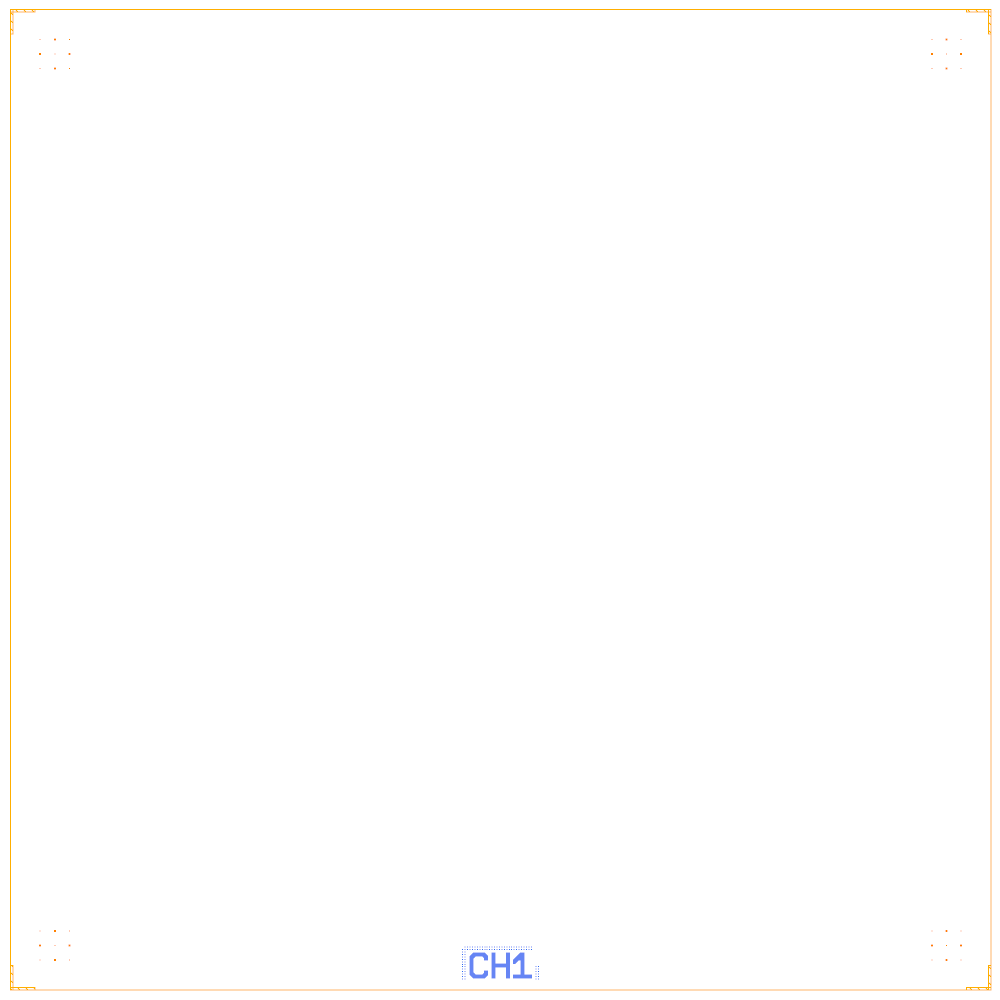

**On the chip so far:** 0 pads · 0 qubits · 1 other components · 0 routes · 0 declared couplings. **This step added** 1 component(s) `CHIP`. The one component is KQC's `Chip` cell; the frame and the device ID belong to the die.

In [8]:
d = Designer("quick_demo_mask_ch1", box=(0, 0, 10000, 10000), chip={"name_chip": "CH1"}, live=LIVE)
d.add("CHIP", "Chip", at=(0, 0), frames_enabled=[])   # KQC's base chip PCell, its own frame off
rebuild(d)
DESIGN, same = save_design(d, OUT / "quick_demo_mask" / "ch1.json")
display(Markdown(same))
CH1 = write_layout(d.result, CHIPS / "CH1.oas", sidecar=False)
print(f"CH1: {DESIGN} → {CH1} ({CH1.stat().st_size / 1e3:.1f} kB); chip boundary {chip_box(CH1)} µm; "
      f"cheese '{cheese_mode(d.result.design)}', {build_cheese(d.result.cell, d.result.design.pdk)} holes")
layout_step(d, STEPS / "4_ch1.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420,
            note="The one component is KQC's `Chip` cell; the frame and the device ID belong to the die.");

## Design 5 · The whole wafer

`w.build(chip_of)` draws the wafer and places a chip on every die whose `ROLE` names one; `chip_of` returns the chip
file, or None for an empty die. Each file is loaded once (the wafer caches by source), so the layout holds one DE1
cell and one CH1 cell, placed 36 and 17 times. `mask_name` adds the mask name on 501/0 in the free band above the top
row of dies, where KQC also puts it; the wafer class has no mask label of its own.

The pictures: the whole wafer; one Demo die (G1, on the ring at the left) with the streets round it; and the street
crossing at G1's top-right corner, where two Demo dies (G1 below, F1 above) meet two empty dies (F2, G2). The streets
are 200 µm wide, the green frames are the 30 µm die outlines on 501/0, the orange L's in the Demo corners are the PDK
dicing markers on 1000/0, the small squares are the alignment grids on 1001/0 and the blue texture is the Demo chip's
ground grid.

sub-cells placed on the wafer: {'chip_DE1': 36, 'chip_CH1': 17} (142 cells in the layout, the chips' own sub-cells included)


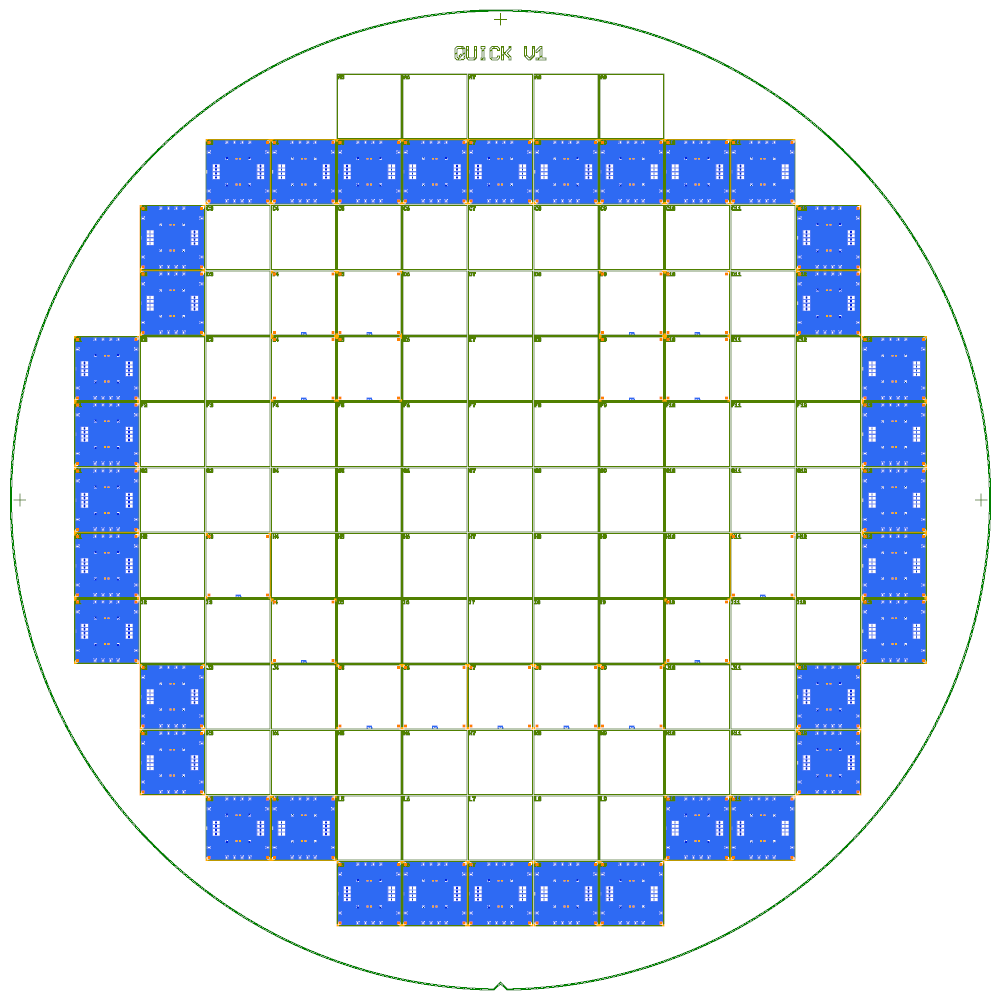

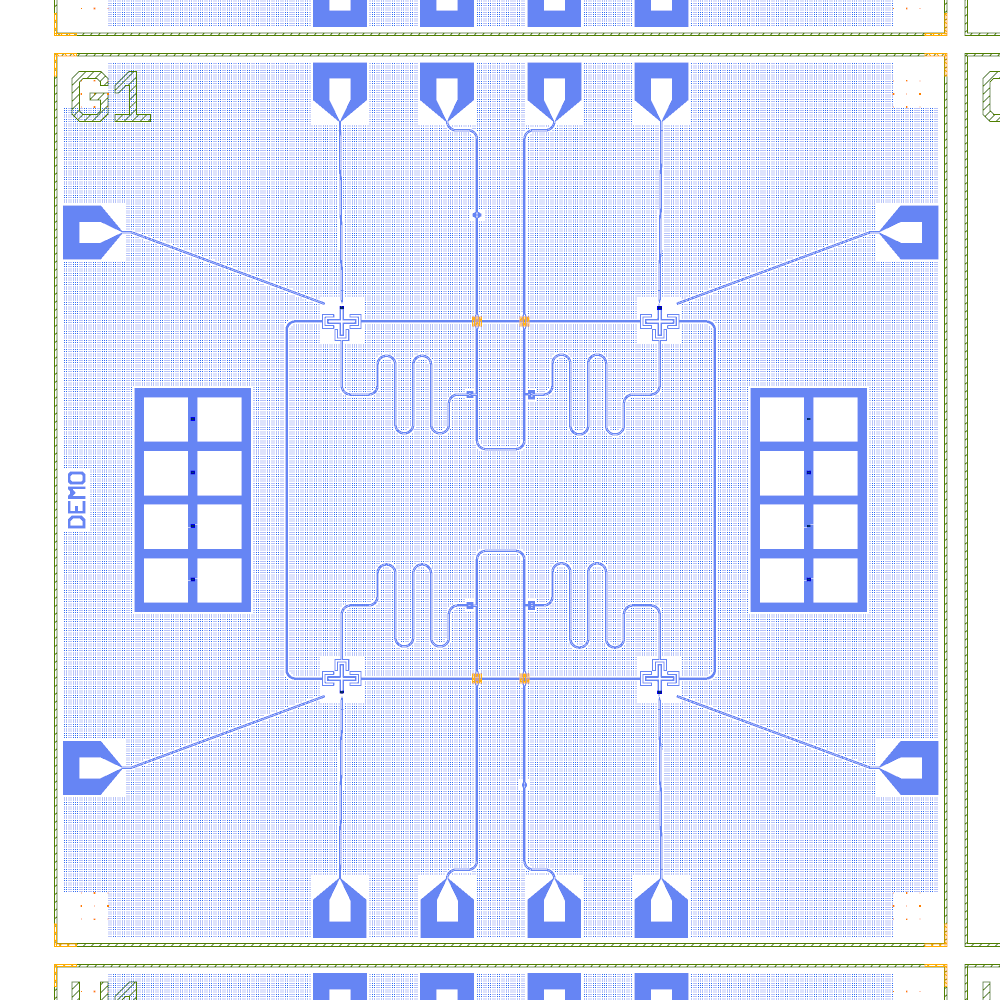

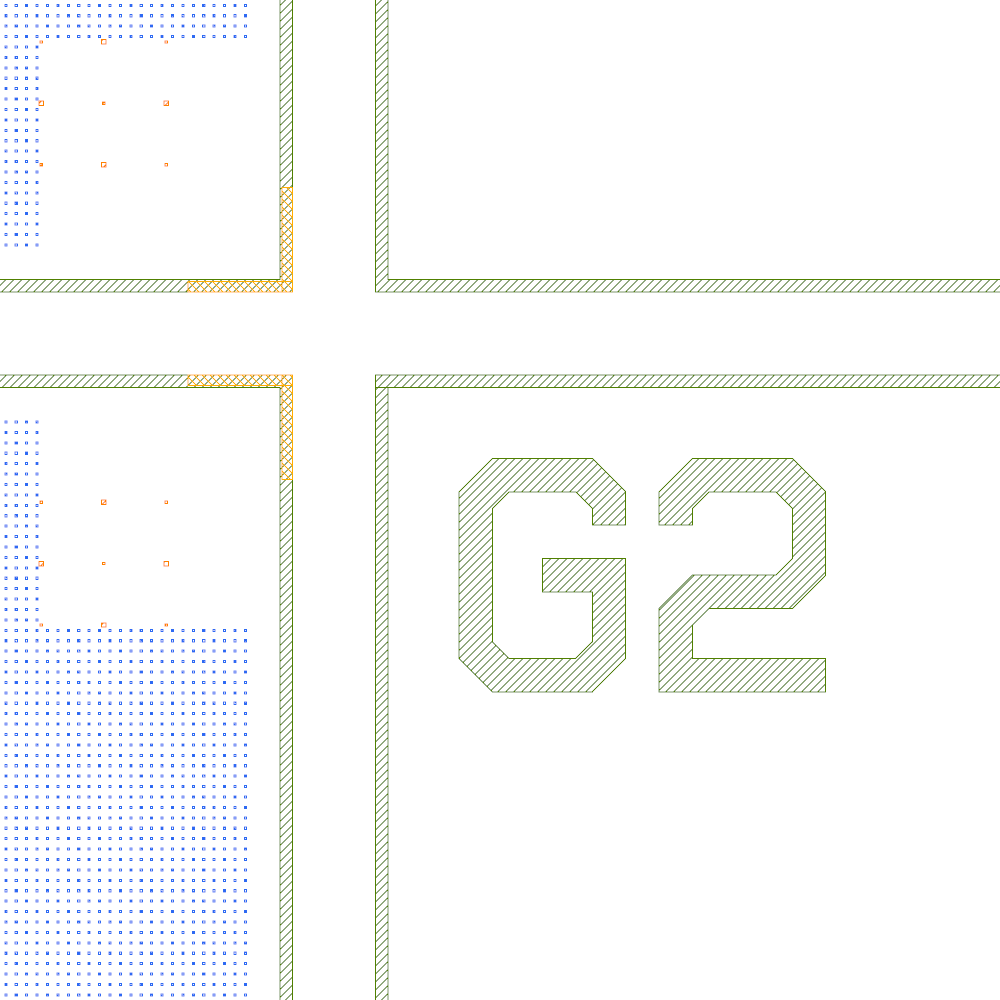

In [9]:
SOURCES = {"DE1": DE1, "CH1": CH1}               # one file per chip


def chip_of(die):
    # the chip file for a die, or None (an empty die keeps its outline and name only)
    role = ROLE[die.name]
    return SOURCES[role] if role else None


def mask_name(layout, top, text="QUICK V1", height_um=3000.0, top_um=70500.0):
    # the mask name on 501/0, centred in x, its top edge top_um above the wafer centre
    reg = pya.TextGenerator.default_generator().text(text, layout.dbu, height_um)
    bb = reg.bbox()
    reg.move(-bb.center().x, round(top_um / layout.dbu) - bb.top)
    top.shapes(layout.layer(QCC_LAYERS["wafer_markers"])).insert(reg)


def wafer_layout(chips=chip_of):
    layout, top = w.build(chips)
    mask_name(layout, top)
    return layout, top


layout, top = wafer_layout()
placed = Counter(layout.cell(inst.cell_index).name for inst in top.each_inst())
print("sub-cells placed on the wafer:", dict(placed),
      f"({layout.cells()} cells in the layout, the chips' own sub-cells included)")
show_layout(layout, STEPS / "5_wafer.png", size=(1000, 1000), width=560)
x0, y0, x1, y1 = w.die("G1").box_um
snap_file(STEPS / "5_wafer.oas", STEPS / "5_die_G1.png", box=(x0 - 600, y0 - 600, x1 + 600, y1 + 600),
          size=(1000, 1000), width=420)
snap_file(STEPS / "5_wafer.oas", STEPS / "5_street.png", box=(x1 - 700, y1 - 1500, x1 + 1700, y1 + 900),
          size=(1000, 1000), width=420);

# Check: the die count and the map against the source

The source fixes the chip counts (36 DE1, 17 CH1) and the map. The first check counts the chips on the wafer and
rebuilds the 15 × 15 map from the dies, cell by cell; the second checks the chips against their dies (size, street,
nothing drawn outside the chip boundary) and that each chip is one cell; the third is the DRC of the CH1 design. The
Demo chip's own DRC is in its notebook.

## Check 1 · Die count and chip map

Every die's `chip` is the chip it carries after the build (the file name, `DE1` or `CH1`). The rebuilt map writes
`D`, `C` or `.` for each of the 225 map cells (`.` for an empty die and for a cell with no die) and must equal the
source's map.

In [ ]:
SPEC = {"DE1": sum(r.count("D") for r in KQC_MAP), "CH1": sum(r.count("C") for r in KQC_MAP)}
got = Counter(die.chip for die in w.dies)
display(Markdown("\n".join([
    "| chip | source map | on the wafer |", "|---|---|---|",
    f"| DE1 (Demo) | {SPEC['DE1']} | {got['DE1']} |",
    f"| CH1 (empty chip) | {SPEC['CH1']} | {got['CH1']} |",
    f"| empty | {sum(r.count('.') for r in KQC_MAP)} map cells | {got[None]} dies |",
    f"| total | {len(KQC_MAP)} × {len(KQC_MAP[0])} = {len(KQC_MAP) * len(KQC_MAP[0])} cells | {w.die_count} dies |",
])))
code_of = {"DE1": "D", "CH1": "C"}
rebuilt = [["."] * len(KQC_MAP[0]) for _ in KQC_MAP]
for die in w.dies:
    r, c = map_cell(die)
    rebuilt[r][c] = code_of.get(die.chip, ".")
rebuilt = ["".join(row) for row in rebuilt]
for k, (a, b) in enumerate(zip(KQC_MAP, rebuilt)):
    print(f"{k + 1:2d}  source {a}   wafer {b}   {'same' if a == b else 'DIFFERENT'}")
assert rebuilt == KQC_MAP and got["DE1"] == SPEC["DE1"] and got["CH1"] == SPEC["CH1"], "the wafer differs from the map"
print("The wafer's chip map equals the source's, cell by cell; no mapped cell is off the wafer:", off_wafer(w) == [])

## Check 2 · The chips on their dies

Each chip's 100/0 boundary is 10 × 10 mm, the die size, so neighbouring chips are one street (200 µm) apart. The
drawn geometry of each chip (every layer except the annotation layers `refpoints` and `instance_names`) must stay
inside that boundary, so no chip reaches into a street or a neighbour. And each chip is one cell in the wafer layout.

In [ ]:
ANNOTATION = ("refpoints", "instance_names")
rows = ["| chip | boundary (µm) | drawn geometry inside it | instances | cells |", "|---|---|---|---|---|"]
for role, path in SOURCES.items():
    ly = pya.Layout()
    ly.read(str(path))
    t = ly.top_cell()
    bound = t.dbbox_per_layer(ly.find_layer(QCC_LAYERS["chip_boundary"]))
    drawn = pya.DBox()
    for li in ly.layer_indexes():
        if ly.get_info(li).name not in ANNOTATION:
            drawn += t.dbbox_per_layer(li)
    inside = bound.contains(drawn.p1) and bound.contains(drawn.p2)
    rows.append(f"| {role} | {bound.width():g} × {bound.height():g} | {'yes' if inside else 'NO: ' + str(drawn)} "
                f"| {placed[f'chip_{role}']} | 1 |")
    assert inside and bound.width() <= w.die_mm * 1000 and bound.height() <= w.die_mm * 1000
display(Markdown("\n".join(rows)))
print(f"street between neighbouring chips: {(PITCH - w.die_mm) * 1000:g} µm (pitch {PITCH:g} mm, die {w.die_mm:g} mm)")

## Check 3 · DRC of the CH1 chip

The DRC reports errors (unfit for fab), warnings (notes to read) and PDK design warnings (values outside the PDK
margins, flagged and never enforced). Expected: no errors and one `frame_margin` warning, because the KQC `Chip`
cell's bounding box is the whole 10 mm chip and so reaches into the 100 µm die margin; the cell draws nothing there.

In [ ]:
display(Markdown(drc_md(d.drc())))

# LOM: nothing new to simulate

The mask adds no circuit: each DE1 die is the Demo chip, whose LOM is in `examples/designs/kqc/demo.ipynb`, and CH1
has no junctions, qubits or resonators.

# Simulate: no jobs

CH1 has no sim groups and the wafer is not simulated, so the export below writes no FEM job; the Demo chip's jobs are
exported by its own notebook.

In [ ]:
jobs = export_sims(DESIGN)                       # one job per sim group of the CH1 design: it has none
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

# Fab: the wafer file, its die table and the fab layers

## Fab 1 · The wafer OAS and its die table

The wafer of Design 5, written to `build/wafer/quick_demo_mask.oas`, with the die table next to it
(`quick_demo_mask.csv`: die, row, column, size, centre in mm, chip). This is what `Wafer.write` writes, plus the
mask name. The chips are in their build layers (the Demo chip's KQC layers, the frame on 100/0 and 1000/0+). The
file stays small because each chip is stored once: the wafer file is about the size of the Demo chip's own file
plus the wafer outline, the labels and CH1.

In [ ]:
WAFER_OAS = WAFER / "quick_demo_mask.oas"
layout, top = wafer_layout()
WAFER_OAS.parent.mkdir(parents=True, exist_ok=True)
layout.write(str(WAFER_OAS))
table = w.write_table(WAFER_OAS.with_suffix(".csv"))
print(f"{WAFER_OAS}: {WAFER_OAS.stat().st_size / 1e3:.0f} kB (DE1.oas alone: {DE1.stat().st_size / 1e3:.0f} kB, "
      f"CH1.oas {CH1.stat().st_size / 1e3:.1f} kB); top cell {top.name}, bbox {top.dbbox()} µm")
print(f"{table}: {w.die_count} rows")
with_chip = [r for r in w.table() if r["chip"]]
display(Markdown("\n".join(["| die | x mm | y mm | chip |", "|---|---|---|---|"] + [
    f"| {r['die']} | {r['x_mm']:.1f} | {r['y_mm']:.1f} | {r['chip']} |" for r in with_chip[:12]])
    + f"\n\n... {len(with_chip)} dies with a chip, {w.die_count} dies in all (`{table.as_posix()}`)"))

## Fab 2 · The fab-layer wafer

The same wafer from each chip's PDK fab mask (`export_fab`): only the PDK fab layers, base etch 1/0 with the cheese,
the filled 3/0 keep-out, the trilayer junction layers 2/0 and 4/0, the spacer 50/0 with 51 to 53/0, airbridges
300/301 and the frame (100/0, 1000/0, 1001/0). Each chip is exported once and placed as one cell, as in Fab 1. Corner rounding (fab only) is skipped unless `FULL_FAB`. The picture zooms on
the street crossing of Design 5 in the fab view.

In [ ]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
from quantcore_circuits.pdk import get_pdk

FAB = CHIPS / "fab"
reports = {}
for role, result in (("DE1", demo), ("CH1", d.result)):
    reports[role] = {}
    export_fab(result, FAB / f"{role}.oas", report=reports[role], cheese=True, rounding=FULL_FAB)
FL = get_pdk().fab_layers
names = sorted(set(reports["DE1"]["written"]) | set(reports["CH1"]["written"]), key=lambda k: (FL[k].layer, FL[k].datatype))
display(Markdown("\n".join(["| fab layer | PDK name | DE1 polygons | CH1 polygons |", "|---|---|---|---|"] + [
    f"| {FL[k].layer}/{FL[k].datatype} | {k} | {reports['DE1']['written'].get(k, 0):,} | "
    f"{reports['CH1']['written'].get(k, 0):,} |" for k in names])
    + f"\n\n**Cheese:** DE1 source `{reports['DE1'].get('cheese_source')}`, {reports['DE1'].get('cheese_holes', 0):,} "
      f"holes; CH1 source `{reports['CH1'].get('cheese_source')}`, {reports['CH1'].get('cheese_holes', 0):,} holes."))
WAFER_FAB = WAFER / "quick_demo_mask_fab.oas"
fab_layout, fab_top = wafer_layout(lambda die: FAB / f"{ROLE[die.name]}.oas" if ROLE[die.name] else None)
fab_layout.write(str(WAFER_FAB))
print(f"{WAFER_FAB}: {WAFER_FAB.stat().st_size / 1e3:.0f} kB; sub-cells",
      dict(Counter(fab_layout.cell(i.cell_index).name for i in fab_top.each_inst())))
snap_file(WAFER_FAB, OUT / "quick_demo_mask_fab.png", box=(x1 - 700, y1 - 1500, x1 + 1700, y1 + 900),
          size=(1000, 1000), width=420);

## Summary

| | |
|---|---|
| **matches the source** | the 15 × 15 chip map cell by cell (36 DE1, 17 CH1), centred on the wafer; the 152.4 mm wafer; 10 mm chips; the 200 µm dicing width; the mask name |
| **differs (PDK)** | dies with a 200 µm street between them (pitch 10.2 mm instead of 10 mm); the PDK edge exclusion (3 mm) and the notch; die names, outlines and alignment crosses on 501/0 instead of KQC's labels and mask markers; empty grid positions drawn as named empty dies; DE1 is the Quantcore Demo rebuild with its own cheese (the source's mask builds without a grid); CH1 has the Quantcore die frame |
| **not applicable** | LOM, FEM and the feedback loop (no circuit of its own); KQC's alternative netlists |
| **files** | `build/wafer/quick_demo_mask.oas` + `.csv` (Fab 1), `build/wafer/quick_demo_mask_fab.oas` (Fab 2), the chip files in `build/wafer/chips/quick_demo_mask/`; the CH1 design `examples/designs/kqc/quick_demo_mask/ch1.json` |
| open | the wafer class draws no mask name (written here on 501/0) and no KQC mask markers |